In [ ]:
import sys
sys.path.append("..")

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import SMOTE

from mindscope.preprocessing import load_data, split_data, build_preprocessor, IQRCapper, TARGET

sns.set_style("whitegrid")

## 1. Loading and basic cleaning

I check the duplicates, the ids and the missing targets before removing them.

In [2]:
raw = pd.read_csv("../data/raw/student_mental_health.csv")

print("Shape:", raw.shape)
print("Duplicated rows:", raw.duplicated().sum())
print("Duplicated student ids:", raw["Student_ID"].duplicated().sum())
print("Missing targets:", raw[TARGET].isnull().sum())

Shape: (2000, 17)
Duplicated rows: 0
Duplicated student ids: 0
Missing targets: 0


In [3]:
df = load_data("../data/raw/student_mental_health.csv")
print("Shape after cleaning:", df.shape)
df.head()

Shape after cleaning: (2000, 16)


,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


## 2. Train and test split

### 2.1 Stratified 80/20 split

In [4]:
X_train, X_test, y_train, y_test = split_data(df)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (1600, 15)
X_test: (400, 15)


### 2.2 Class proportions in train and test

In [5]:
print("Train distribution (%)")
print((y_train.value_counts(normalize=True) * 100).round(2))
print()
print("Test distribution (%)")
print((y_test.value_counts(normalize=True) * 100).round(2))

Train distribution (%)
Mental_Health_Risk
High      34.0
Medium    33.0
Low       33.0
Name: proportion, dtype: float64

Test distribution (%)
Mental_Health_Risk
High      34.0
Medium    33.0
Low       33.0
Name: proportion, dtype: float64


## 3. Missing values

### 3.1 Numerical and categorical columns

I separate the columns by type because they need different transformations.

In [6]:
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()

print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)

Numerical columns: ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']
Categorical columns: ['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']


### 3.2 Missing values in the training set

I look at the missing values in the training set, and I will fill the numerical ones with the median and the categorical ones with the most frequent value.

In [7]:
missing = X_train.isnull().sum()
print(missing[missing > 0])
print("Total:", missing.sum())

Sleep_Hours           54
GPA                   36
Social_Media_Hours    48
Financial_Stress      76
Family_Support        36
Attendance_Rate       39
Diet_Quality          55
dtype: int64
Total: 344


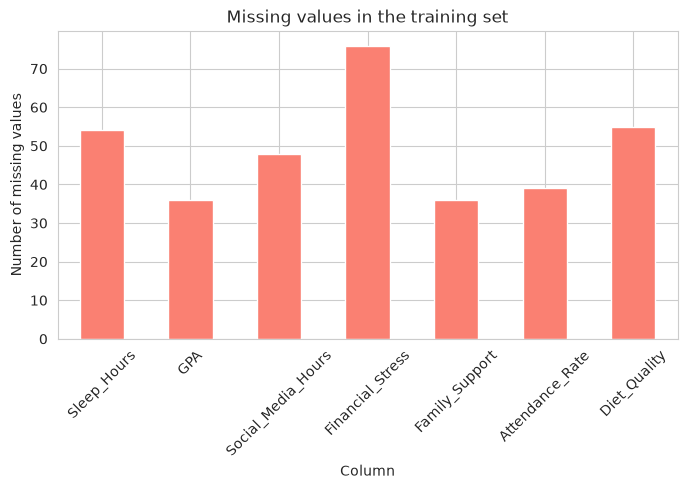

In [8]:
if missing.sum() > 0:
    plt.figure(figsize=(8, 4))
    missing[missing > 0].plot(kind="bar", color="salmon")
    plt.title("Missing values in the training set")
    plt.xlabel("Column")
    plt.ylabel("Number of missing values")
    plt.xticks(rotation=45)
    plt.show()

## 4. Outliers

### 4.1 Detecting and capping outliers (IQR)

I cap the extreme values with the IQR method, using only the training data to compute the limits.

In [9]:
filled = X_train[num_cols].fillna(X_train[num_cols].median())

capper = IQRCapper()
capped = pd.DataFrame(capper.fit_transform(filled), columns=num_cols)

changed = (filled.values != capped.values).sum(axis=0)
outliers_count = pd.Series(changed, index=num_cols)
print(outliers_count)

Age                      2
Year_of_Study            0
Sleep_Hours              9
Study_Hours_Per_Week     7
GPA                      8
Social_Media_Hours      16
Screen_Time_Hours        7
Financial_Stress         0
Family_Support           0
Attendance_Rate         10
dtype: int64


### 4.2 Before and after capping

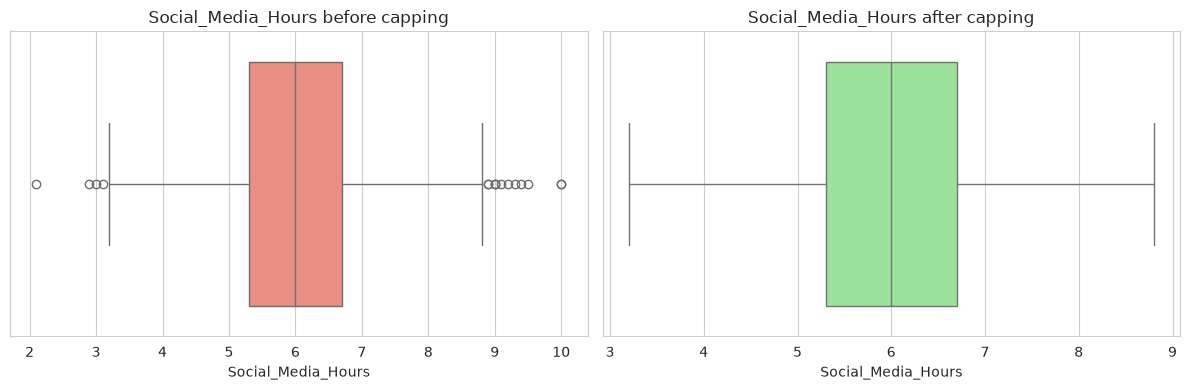

In [10]:
col = outliers_count.idxmax()

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.boxplot(x=filled[col], color="salmon")
plt.title(col + " before capping")
plt.xlabel(col)

plt.subplot(1, 2, 2)
sns.boxplot(x=capped[col], color="lightgreen")
plt.title(col + " after capping")
plt.xlabel(col)

plt.tight_layout()
plt.show()

## 5. Encoding

The models only understand numbers, so the categorical columns are transformed with one-hot encoding and ordinal encoding.

In [11]:
print(X_train[cat_cols].nunique())
print()
for col in cat_cols:
    print(col, ":", X_train[col].dropna().unique())

Gender                            3
Physical_Activity                 3
Part_Time_Job                     2
Diet_Quality                      3
Previous_Mental_Health_History    2
dtype: int64

Gender : <ArrowStringArray>
['Female', 'Male', 'Non-binary']
Length: 3, dtype: str
Physical_Activity : <ArrowStringArray>
['Moderate', 'High', 'Low']
Length: 3, dtype: str
Part_Time_Job : <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
Diet_Quality : <ArrowStringArray>
['Average', 'Poor', 'Good']
Length: 3, dtype: str
Previous_Mental_Health_History : <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str


## 6. Scaling and preprocessing pipeline

### 6.1 Building the pipeline and fitting it on the train set

I put imputation, capping, scaling and encoding in one `ColumnTransformer`, then fit it on the train set only and apply it to the test set.

In [12]:
preprocessor = build_preprocessor(X_train)

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print("Train shape:", X_train_prep.shape)
print("Test shape:", X_test_prep.shape)

Train shape: (1600, 23)
Test shape: (400, 23)


### 6.2 Checking the transformed data

In [13]:
feature_names = preprocessor.get_feature_names_out()
train_prep_df = pd.DataFrame(X_train_prep, columns=feature_names)

print("Missing values after preprocessing:", train_prep_df.isnull().sum().sum())
train_prep_df.head()

Missing values after preprocessing: 0


,num__Age,num__Year_of_Study,num__Sleep_Hours,num__Study_Hours_Per_Week,num__GPA,num__Social_Media_Hours,num__Screen_Time_Hours,num__Financial_Stress,num__Family_Support,num__Attendance_Rate,...,cat__Physical_Activity_High,cat__Physical_Activity_Low,cat__Physical_Activity_Moderate,cat__Part_Time_Job_No,cat__Part_Time_Job_Yes,cat__Diet_Quality_Average,cat__Diet_Quality_Good,cat__Diet_Quality_Poor,cat__Previous_Mental_Health_History_No,cat__Previous_Mental_Health_History_Yes
0,-0.063471,-0.471636,-1.407010,-0.239251,0.075154,0.152640,1.102483,0.713748,0.643008,-1.262159,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
1,0.876838,-1.232340,-1.679538,-1.334412,-0.979124,0.333883,0.195167,-0.842691,0.368687,-0.474507,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
2,-1.003780,-0.471636,0.409842,-0.517387,-1.037695,-0.300466,-0.833123,-0.305988,0.752736,0.777296,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
3,0.876838,-1.232340,1.409111,-0.082800,0.895148,0.786989,1.102483,0.821088,-0.948052,-0.221334,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
4,0.406684,0.289067,0.409842,0.664691,-0.276272,-0.391088,-0.349222,0.660077,0.697872,-1.473137,...,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0


### 6.3 Checking the scaling

In [14]:
num_features = [c for c in feature_names if c.startswith("num__")]
train_prep_df[num_features].describe().loc[["mean", "std"]].round(2)

,num__Age,num__Year_of_Study,num__Sleep_Hours,num__Study_Hours_Per_Week,num__GPA,num__Social_Media_Hours,num__Screen_Time_Hours,num__Financial_Stress,num__Family_Support,num__Attendance_Rate
mean,-0.0,-0.0,0.0,0.0,0.0,0.0,-0.0,-0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 7. Class imbalance

### 7.1 Ratio between the classes

I compute the ratio between the biggest and the smallest class to decide if SMOTE is needed.

In [15]:
counts = y_train.value_counts()
print(counts)
print("Ratio majority / minority:", round(counts.max() / counts.min(), 2))

Mental_Health_Risk
High      544
Medium    528
Low       528
Name: count, dtype: int64
Ratio majority / minority: 1.03


### 7.2 SMOTE on the training set

SMOTE creates new examples of the minority classes, and it must only be applied on the training set.

In [16]:
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_prep, y_train)

print("Before SMOTE:")
print(y_train.value_counts())
print()
print("After SMOTE:")
print(pd.Series(y_train_smote).value_counts())

Before SMOTE:
Mental_Health_Risk
High      544
Medium    528
Low       528
Name: count, dtype: int64

After SMOTE:
Mental_Health_Risk
Medium    544
Low       544
High      544
Name: count, dtype: int64


### 7.3 Before and after SMOTE

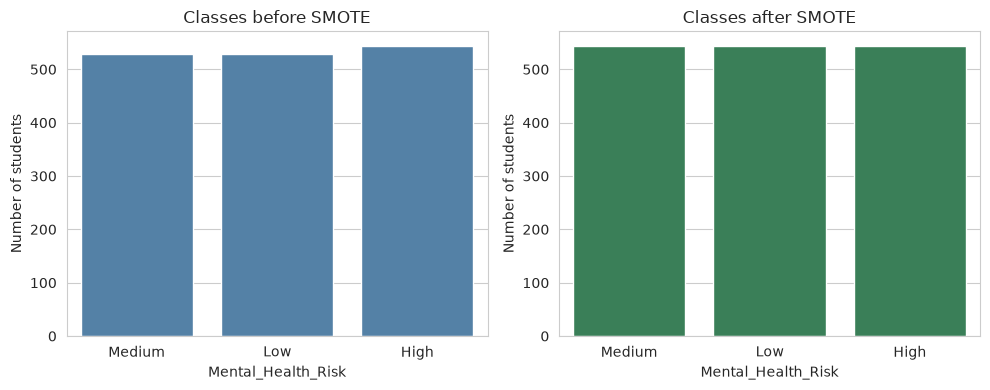

In [17]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.countplot(x=y_train, color="steelblue")
plt.title("Classes before SMOTE")
plt.xlabel(TARGET)
plt.ylabel("Number of students")

plt.subplot(1, 2, 2)
sns.countplot(x=y_train_smote, color="seagreen")
plt.title("Classes after SMOTE")
plt.xlabel(TARGET)
plt.ylabel("Number of students")

plt.tight_layout()
plt.show()

In the final pipeline SMOTE is a step before the model, so it is only applied on the training folds and never on the test data.

## 8. Saving the train and test sets

I save the split data in `data/processed` so the next notebooks use exactly the same train and test sets.

In [18]:
os.makedirs("../data/processed", exist_ok=True)

X_train.to_csv("../data/processed/X_train.csv", index=False)
X_test.to_csv("../data/processed/X_test.csv", index=False)
y_train.to_csv("../data/processed/y_train.csv", index=False)
y_test.to_csv("../data/processed/y_test.csv", index=False)

print(os.listdir("../data/processed"))

['X_train.csv', 'X_test.csv', 'y_train.csv', 'y_test.csv', '.gitkeep']
